<a href="https://colab.research.google.com/github/DairoGit/chatbot-logbook-maestria/blob/main/Chatbot_Logbook_Avance_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

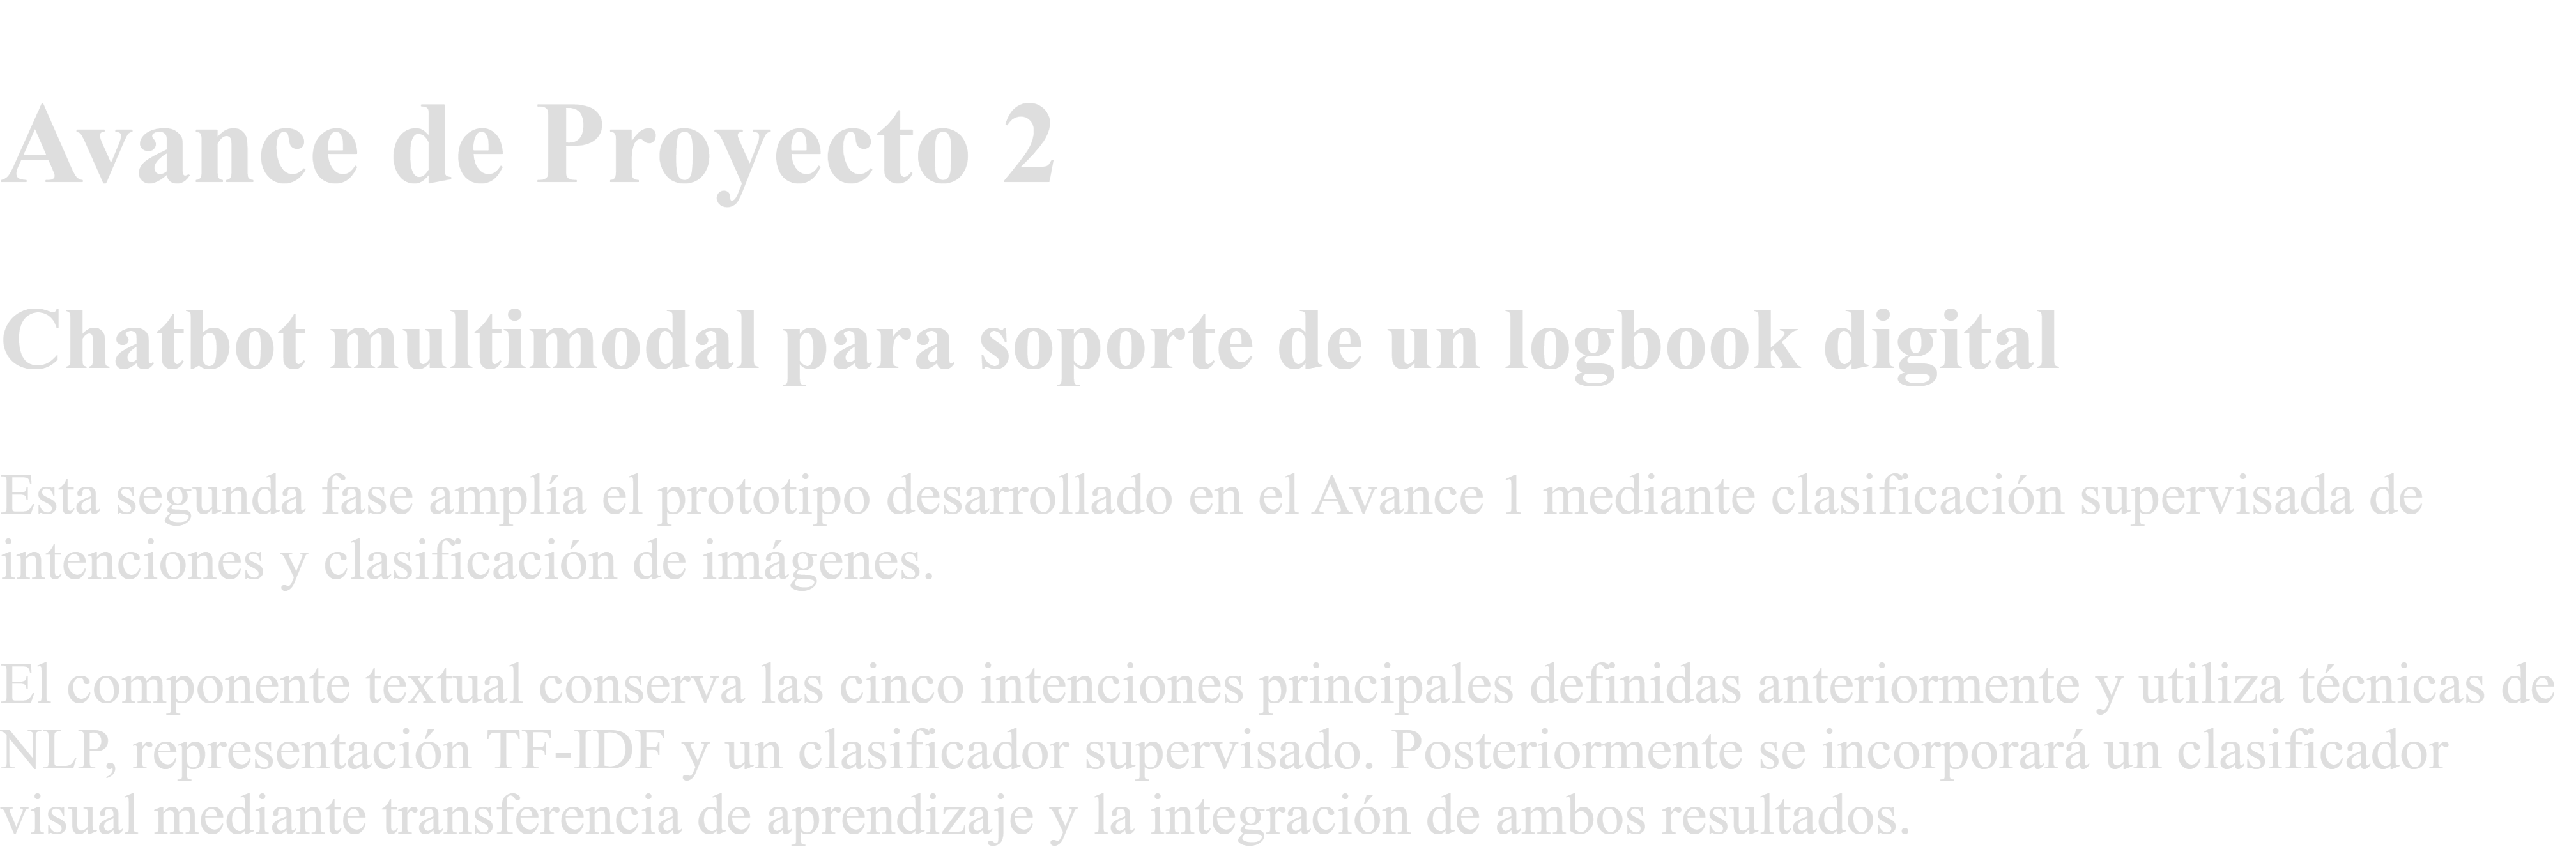

In [1]:
# ============================================================
# CELDA 1 - CONFIGURACIÓN DEL ENTORNO
# ============================================================

import sys
import platform

print("Versión completa:", sys.version)
print(
    "Versión simplificada:",
    f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}"
)
print("Sistema:", platform.platform())

if sys.version_info >= (3, 10):
    print("Resultado: versión de Python compatible.")
else:
    raise RuntimeError(
        "El proyecto requiere Python 3.10 o superior."
    )

Versión completa: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Versión simplificada: 3.13.18
Sistema: Linux-6.6.159+-x86_64-with-glibc2.39
Resultado: versión de Python compatible.


In [13]:
# ============================================================
# CELDA 2 - LIBRERÍAS PARA PROCESAMIENTO DE TEXTO
# ============================================================

import re
import unicodedata
import random

import numpy as np
import pandas as pd
import nltk
import sklearn

from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem.snowball import SpanishStemmer

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Descargar el recurso de stopwords en español
nltk.download("stopwords", quiet=True)

print("Versión de NLTK:", nltk.__version__)
print("Versión de scikit-learn:", sklearn.__version__)
print("Resultado: librerías cargadas correctamente.")

Versión de NLTK: 3.9.1
Versión de scikit-learn: 1.6.1
Resultado: librerías cargadas correctamente.


In [14]:
# ============================================================
# CELDA 3 - CONFIGURACIÓN DEL PREPROCESAMIENTO NLP
# ============================================================

# Tokenizador basado en expresiones regulares
tokenizer = RegexpTokenizer(r"\w+")

# Stemmer para español
stemmer = SpanishStemmer()

# Cargar stopwords en español
spanish_stopwords = set(stopwords.words("spanish"))

# Las negaciones pueden cambiar el significado de una frase.
# Por esta razón se conservan durante el preprocesamiento.
negations_to_keep = {"no", "ni", "nunca"}

spanish_stopwords = spanish_stopwords - negations_to_keep

print("Cantidad de stopwords utilizadas:", len(spanish_stopwords))
print("Negaciones conservadas:", sorted(negations_to_keep))
print("Resultado: configuración NLP completada.")


Cantidad de stopwords utilizadas: 311
Negaciones conservadas: ['ni', 'no', 'nunca']
Resultado: configuración NLP completada.


In [15]:
# ============================================================
# CELDA 4 - PREPROCESAMIENTO DEL TEXTO
# ============================================================

def remove_accents(text):
    """
    Elimina acentos para reducir variaciones ortográficas
    durante el procesamiento del texto.
    """

    normalized = unicodedata.normalize("NFD", str(text))

    return "".join(
        character
        for character in normalized
        if unicodedata.category(character) != "Mn"
    )


def preprocess_text(text):
    """
    Aplica las cuatro técnicas principales de NLP requeridas:

    1. Normalización
    2. Tokenización
    3. Eliminación de stopwords
    4. Stemming

    El resultado se utilizará posteriormente como entrada
    para la representación mediante TF-IDF.
    """

    # Manejo de valores nulos
    if text is None:
        return ""

    # Conversión segura a texto y eliminación
    # de espacios innecesarios
    text = str(text).strip()

    # Manejo de cadenas vacías
    if not text:
        return ""

    # --------------------------------------------------------
    # 1. NORMALIZACIÓN
    # --------------------------------------------------------

    # Conversión a minúsculas
    text = text.lower()

    # Eliminación de acentos
    text = remove_accents(text)

    # --------------------------------------------------------
    # 2. TOKENIZACIÓN
    # --------------------------------------------------------

    tokens = tokenizer.tokenize(text)

    # --------------------------------------------------------
    # 3. ELIMINACIÓN DE STOPWORDS
    # 4. STEMMING
    # --------------------------------------------------------

    processed_tokens = [
        stemmer.stem(token)
        for token in tokens
        if token not in spanish_stopwords
    ]

    # El vectorizador TF-IDF recibirá nuevamente
    # los tokens como una cadena procesada.
    return " ".join(processed_tokens)


print("Resultado: función preprocess_text preparada correctamente.")

Resultado: función preprocess_text preparada correctamente.


In [16]:
# ============================================================
# CELDA 5 - PRUEBA DEL PREPROCESAMIENTO
# ============================================================

test_messages = [
    "No puedo cargar mi archivo PDF en el logbook.",
    "Mi cuenta nueva todavía no aparece.",
    "La página nunca termina de cargar.",
    "No tengo permisos para acceder a esta función."
]

print("=" * 70)
print("PRUEBA DEL PREPROCESAMIENTO DE TEXTO")
print("=" * 70)

for number, message in enumerate(test_messages, start=1):

    processed_message = preprocess_text(message)

    print(f"\nEjemplo {number}")
    print("Original:  ", message)
    print("Procesado: ", processed_message)

print("\n" + "=" * 70)
print("Resultado: prueba de preprocesamiento finalizada.")

PRUEBA DEL PREPROCESAMIENTO DE TEXTO

Ejemplo 1
Original:   No puedo cargar mi archivo PDF en el logbook.
Procesado:  no pued carg archiv pdf logbook

Ejemplo 2
Original:   Mi cuenta nueva todavía no aparece.
Procesado:  cuent nuev todavi no aparec

Ejemplo 3
Original:   La página nunca termina de cargar.
Procesado:  pagin nunc termin carg

Ejemplo 4
Original:   No tengo permisos para acceder a esta función.
Procesado:  no permis acced funcion

Resultado: prueba de preprocesamiento finalizada.


In [17]:
# ================================================================
# CELDA 6 - CONSTRUCCIÓN Y VALIDACIÓN DEL DATASET TEXTUAL
# ================================================================

import pandas as pd

# Ejemplos etiquetados para las cinco intenciones del proyecto.
# Se incluyen distintas formas de expresar cada problema.
intent_examples = {
    "file_upload_issue": [
        "No puedo cargar mi archivo en el logbook",
        "El sistema no me deja subir un PDF",
        "Tengo problemas para adjuntar un archivo",
        "Mi documento no se carga",
        "No puedo subir los resultados al logbook",
        "La carga del archivo falla",
        "Intento adjuntar un PDF pero no funciona",
        "El logbook rechaza mi archivo",
        "No puedo cargar un documento",
        "Mi archivo no aparece después de subirlo",
        "Tengo un error al cargar un archivo",
        "La aplicación no acepta mi documento",
        "No puedo adjuntar los resultados",
        "El archivo no termina de cargar",
        "Quiero subir un PDF pero aparece un error",
        "No se completa la carga de mi documento",
        "El sistema falla cuando intento adjuntar un archivo",
        "No puedo agregar un archivo al registro",
        "La carga de mi PDF no funciona",
        "Tengo dificultades para subir un documento"
    ],

    "access_permission_issue": [
        "No tengo permisos para acceder a esta función",
        "No puedo entrar a esta sección del logbook",
        "El sistema indica que no tengo acceso",
        "No tengo permiso para utilizar esta opción",
        "No puedo acceder al registro",
        "Me aparece un error de permisos",
        "El logbook no me permite entrar a esta función",
        "Necesito acceso a esta sección",
        "No puedo abrir esta opción por falta de permisos",
        "Mi usuario no tiene acceso",
        "El sistema bloquea mi acceso a esta función",
        "No tengo autorización para entrar",
        "No puedo consultar esta sección",
        "Me faltan permisos en el logbook",
        "El acceso a esta función está restringido",
        "No puedo utilizar esta opción con mi cuenta",
        "El sistema dice que mi acceso está denegado",
        "No tengo los permisos necesarios",
        "Mi cuenta no puede acceder a esta sección",
        "No puedo ingresar por un problema de permisos"
    ],

    "account_sync_issue": [
        "Mi cuenta nueva todavía no aparece",
        "Mi usuario nuevo no está disponible en el logbook",
        "La cuenta no se ha sincronizado",
        "No aparece mi usuario después de crear la cuenta",
        "Mi cuenta nueva aún no está visible",
        "El logbook todavía no reconoce mi usuario",
        "Tengo un problema de sincronización con mi cuenta",
        "Mi usuario no aparece en el sistema",
        "La cuenta fue creada pero no se muestra",
        "Mi cuenta todavía no está disponible",
        "El usuario nuevo no se ha sincronizado",
        "No encuentro mi cuenta en el logbook",
        "Mi perfil aún no aparece en la aplicación",
        "La sincronización de mi usuario no se completó",
        "Mi cuenta recién creada no funciona",
        "El sistema todavía no muestra mi usuario",
        "La cuenta nueva no aparece en la aplicación",
        "Mi usuario sigue pendiente de sincronización",
        "No puedo encontrar mi cuenta recién creada",
        "Parece que mi usuario no se sincronizó"
    ],

    "browser_issue": [
        "La página nunca termina de cargar",
        "El logbook se queda cargando en el navegador",
        "La pantalla aparece en blanco",
        "La aplicación no carga correctamente",
        "Tengo problemas al abrir el logbook en el navegador",
        "La página no responde",
        "El sistema se queda cargando",
        "El logbook muestra una pantalla en blanco",
        "La aplicación no abre correctamente",
        "La página dejó de responder",
        "Tengo un problema con el navegador",
        "El logbook no carga en mi navegador",
        "La pantalla se queda congelada",
        "La página tarda demasiado en cargar",
        "El navegador no muestra correctamente la aplicación",
        "La aplicación se queda en la pantalla de carga",
        "El sitio no termina de abrir",
        "El logbook funciona mal en el navegador",
        "La página permanece cargando sin avanzar",
        "No puedo visualizar correctamente el logbook"
    ],

    "inactive_account_issue": [
        "Mi cuenta aparece como inactiva",
        "Mi usuario está deshabilitado",
        "La cuenta se encuentra bloqueada",
        "No puedo entrar porque mi cuenta está inactiva",
        "Mi usuario fue desactivado",
        "El sistema dice que mi cuenta está bloqueada",
        "Regresé después de un tiempo y mi cuenta está inactiva",
        "Mi cuenta aparece deshabilitada",
        "No puedo usar el logbook porque mi usuario está bloqueado",
        "El sistema indica que mi usuario está inactivo",
        "Necesito reactivar mi cuenta",
        "Mi usuario ya no está activo",
        "La cuenta fue deshabilitada",
        "No puedo acceder porque mi cuenta está bloqueada",
        "Mi cuenta dejó de estar activa",
        "El logbook indica que mi usuario fue desactivado",
        "Después de un tiempo sin usarlo mi cuenta está inactiva",
        "Mi usuario necesita ser reactivado",
        "El sistema muestra mi cuenta como deshabilitada",
        "No puedo iniciar porque mi usuario está inactivo"
    ]
}

# Convertir los ejemplos a un DataFrame.
records = [
    {"texto": text, "intencion": intent}
    for intent, examples in intent_examples.items()
    for text in examples
]

df_text = pd.DataFrame(records)

# Intenciones válidas.
valid_intents = set(intent_examples.keys())

# Validaciones básicas de calidad.
empty_rows = int(
    df_text["texto"].isna().sum()
    + df_text["texto"].fillna("").str.strip().eq("").sum()
)
duplicates = int(df_text.duplicated(subset=["texto"]).sum())
invalid_labels = int((~df_text["intencion"].isin(valid_intents)).sum())

# Resumen del dataset.
print("=" * 60)
print("RESUMEN DEL DATASET TEXTUAL")
print("=" * 60)

print(f"Total de registros: {len(df_text)}")
print(f"Total de intenciones: {df_text['intencion'].nunique()}")

print("\nDistribución por intención:")
print(df_text["intencion"].value_counts().sort_index())

print("\nValidación:")
print(f"Entradas vacías: {empty_rows}")
print(f"Duplicados exactos: {duplicates}")
print(f"Etiquetas inválidas: {invalid_labels}")

print("\nPrimeros 5 registros:")
print(df_text.head().to_string(index=False))

print("\nResultado: dataset textual construido y validado.")

RESUMEN DEL DATASET TEXTUAL
Total de registros: 100
Total de intenciones: 5

Distribución por intención:
intencion
access_permission_issue    20
account_sync_issue         20
browser_issue              20
file_upload_issue          20
inactive_account_issue     20
Name: count, dtype: int64

Validación:
Entradas vacías: 0
Duplicados exactos: 0
Etiquetas inválidas: 0

Primeros 5 registros:
                                   texto         intencion
No puedo cargar mi archivo en el logbook file_upload_issue
      El sistema no me deja subir un PDF file_upload_issue
Tengo problemas para adjuntar un archivo file_upload_issue
                Mi documento no se carga file_upload_issue
No puedo subir los resultados al logbook file_upload_issue

Resultado: dataset textual construido y validado.


In [18]:
# ================================================================
# CELDA 7 - DIVISIÓN DEL DATASET EN ENTRENAMIENTO Y PRUEBA
# ================================================================

from sklearn.model_selection import train_test_split

# Variables de entrada y etiquetas.
X = df_text["texto"]
y = df_text["intencion"]

# División 80/20 manteniendo la proporción de cada intención.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("DIVISIÓN DEL DATASET TEXTUAL")
print("=" * 60)

print(f"Registros de entrenamiento: {len(X_train)}")
print(f"Registros de prueba: {len(X_test)}")

print("\nDistribución en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nDistribución en prueba:")
print(y_test.value_counts().sort_index())

print("\nResultado: división estratificada completada.")

DIVISIÓN DEL DATASET TEXTUAL
Registros de entrenamiento: 80
Registros de prueba: 20

Distribución en entrenamiento:
intencion
access_permission_issue    16
account_sync_issue         16
browser_issue              16
file_upload_issue          16
inactive_account_issue     16
Name: count, dtype: int64

Distribución en prueba:
intencion
access_permission_issue    4
account_sync_issue         4
browser_issue              4
file_upload_issue          4
inactive_account_issue     4
Name: count, dtype: int64

Resultado: división estratificada completada.


In [21]:
# ============================================================
# CELDA 8 - REPRESENTACIÓN TF-IDF Y ENTRENAMIENTO DEL MODELO
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC


def preprocess_series(texts):
    """
    Aplica preprocess_text a cada entrada recibida por el Pipeline.

    Compatible tanto con Series de pandas utilizadas durante
    el entrenamiento como con listas utilizadas en predicciones
    individuales.
    """
    return [preprocess_text(text) for text in texts]


text_model = Pipeline([
    (
        "preprocessing",
        FunctionTransformer(
            preprocess_series,
            validate=False
        )
    ),
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LinearSVC(
            class_weight="balanced",
            random_state=42
        )
    )
])


# Entrenamiento únicamente con el conjunto reservado para este propósito
text_model.fit(X_train, y_train)

print("=" * 65)
print("ENTRENAMIENTO DEL CLASIFICADOR TEXTUAL")
print("=" * 65)

print("Modelo: LinearSVC")
print("Representación: TF-IDF")
print("N-gramas: unigramas y bigramas")
print("Registros utilizados para entrenamiento:", len(X_train))

print("\nClases aprendidas:")
for class_name in text_model.named_steps["classifier"].classes_:
    print("-", class_name)

print("\nResultado: entrenamiento completado correctamente.")

ENTRENAMIENTO DEL CLASIFICADOR TEXTUAL
Modelo: LinearSVC
Representación: TF-IDF
N-gramas: unigramas y bigramas
Registros utilizados para entrenamiento: 80

Clases aprendidas:
- access_permission_issue
- account_sync_issue
- browser_issue
- file_upload_issue
- inactive_account_issue

Resultado: entrenamiento completado correctamente.


EVALUACIÓN DEL CLASIFICADOR TEXTUAL

Accuracy: 0.9000

Classification report:
                         precision    recall  f1-score   support

access_permission_issue       0.80      1.00      0.89         4
     account_sync_issue       1.00      0.75      0.86         4
          browser_issue       1.00      1.00      1.00         4
      file_upload_issue       1.00      1.00      1.00         4
 inactive_account_issue       0.75      0.75      0.75         4

               accuracy                           0.90        20
              macro avg       0.91      0.90      0.90        20
           weighted avg       0.91      0.90      0.90        20



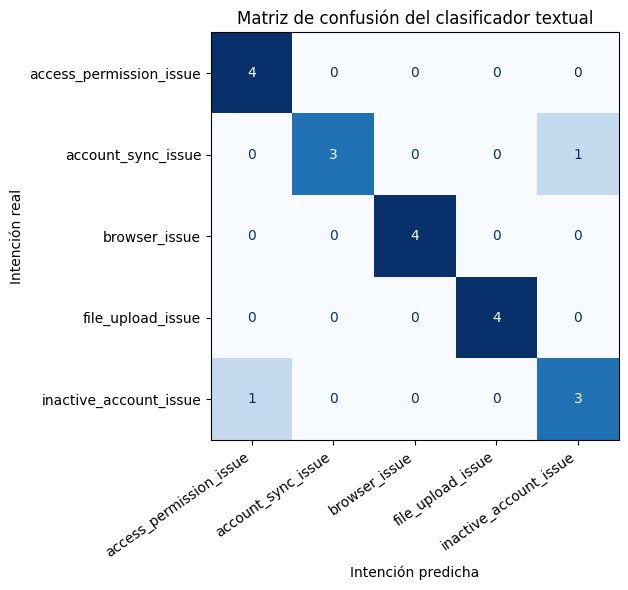


Resultado: evaluación del clasificador completada.


In [9]:
# ================================================================
# CELDA 9 - EVALUACIÓN DEL CLASIFICADOR TEXTUAL
# ================================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predicciones sobre el conjunto reservado de prueba
y_pred = text_model.predict(X_test)

# Clases del modelo
class_names = text_model.named_steps["classifier"].classes_

# Métricas
accuracy = accuracy_score(y_test, y_pred)

report = classification_report(
    y_test,
    y_pred,
    labels=class_names,
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

# ------------------------------------------------
# RESULTADOS NUMÉRICOS
# ------------------------------------------------

print("=" * 70)
print("EVALUACIÓN DEL CLASIFICADOR TEXTUAL")
print("=" * 70)

print(f"\nAccuracy: {accuracy:.4f}")

print("\nClassification report:")
print(report)

# ------------------------------------------------
# MATRIZ DE CONFUSIÓN GRÁFICA
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Matriz de confusión del clasificador textual")
ax.set_xlabel("Intención predicha")
ax.set_ylabel("Intención real")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("\nResultado: evaluación del clasificador completada.")

In [1]:
# ================================================================
# CELDA 10 - GENERACIÓN DEL DATASET VISUAL SINTÉTICO
# ================================================================

from pathlib import Path
from PIL import Image, ImageDraw
import random

# Semilla para reproducibilidad
random.seed(42)

# Configuración
DATASET_DIR = Path("/content/dataset_visual")
CLASSES = ["access_error", "upload_error", "loading_error"]
IMAGES_PER_CLASS = 30
IMAGE_SIZE = (640, 420)

# Crear carpetas
for class_name in CLASSES:
    (DATASET_DIR / class_name).mkdir(parents=True, exist_ok=True)


def create_logbook_screen(class_name, index):
    """
    Genera una interfaz sintética de un logbook ficticio.
    Las tres categorías comparten el mismo estilo general,
    pero contienen indicadores visuales diferentes.
    """

    width, height = IMAGE_SIZE

    # Variaciones controladas
    background_colors = [
        (244, 247, 250),
        (248, 249, 252),
        (240, 244, 248)
    ]

    accent_colors = [
        (38, 110, 140),
        (50, 120, 145),
        (40, 100, 135)
    ]

    background = random.choice(background_colors)
    accent = random.choice(accent_colors)

    image = Image.new("RGB", IMAGE_SIZE, background)
    draw = ImageDraw.Draw(image)

    # ------------------------------------------------------------
    # Estructura general del logbook ficticio
    # ------------------------------------------------------------

    # Barra superior
    draw.rectangle(
        [0, 0, width, 55],
        fill=accent
    )

    draw.text(
        (25, 18),
        "DIGITAL LOGBOOK",
        fill="white"
    )

    # Panel lateral
    sidebar_width = random.randint(120, 155)

    draw.rectangle(
        [0, 55, sidebar_width, height],
        fill=(225, 231, 236)
    )

    # Opciones ficticias del menú
    menu_items = ["Home", "Records", "Files", "Profile"]

    y = 90

    for item in menu_items:
        draw.rectangle(
            [18, y, sidebar_width - 18, y + 28],
            outline=(185, 195, 205),
            width=1
        )

        draw.text(
            (28, y + 8),
            item,
            fill=(65, 70, 75)
        )

        y += 45

    # Área principal
    panel_x1 = sidebar_width + 30
    panel_y1 = 85
    panel_x2 = width - 30
    panel_y2 = height - 35

    draw.rectangle(
        [panel_x1, panel_y1, panel_x2, panel_y2],
        fill="white",
        outline=(205, 210, 215),
        width=2
    )

    # Variación ligera de posición
    offset_x = random.randint(-10, 10)
    offset_y = random.randint(-8, 8)

    center_x = (panel_x1 + panel_x2) // 2 + offset_x
    center_y = (panel_y1 + panel_y2) // 2 + offset_y

    # ------------------------------------------------------------
    # CLASE 1 - ACCESS ERROR
    # ------------------------------------------------------------

    if class_name == "access_error":

        # Símbolo visual de restricción
        draw.rectangle(
            [center_x - 35, center_y - 65,
             center_x + 35, center_y + 5],
            outline=(180, 65, 65),
            width=4
        )

        draw.rectangle(
            [center_x - 18, center_y - 85,
             center_x + 18, center_y - 55],
            outline=(180, 65, 65),
            width=4
        )

        messages = [
            "Access restricted",
            "Permission required",
            "Access denied",
            "Insufficient permissions"
        ]

        draw.text(
            (center_x - 75, center_y + 30),
            random.choice(messages),
            fill=(150, 50, 50)
        )

    # ------------------------------------------------------------
    # CLASE 2 - UPLOAD ERROR
    # ------------------------------------------------------------

    elif class_name == "upload_error":

        # Zona ficticia para archivos
        draw.rectangle(
            [center_x - 120, center_y - 65,
             center_x + 120, center_y + 20],
            outline=(90, 120, 145),
            width=3
        )

        filenames = [
            "report.pdf",
            "results.csv",
            "experiment.pdf",
            "data_file.csv"
        ]

        draw.text(
            (center_x - 90, center_y - 35),
            random.choice(filenames),
            fill=(60, 70, 80)
        )

        messages = [
            "Upload failed",
            "File could not be uploaded",
            "Upload error",
            "File upload incomplete"
        ]

        draw.text(
            (center_x - 90, center_y + 45),
            random.choice(messages),
            fill=(175, 70, 55)
        )

    # ------------------------------------------------------------
    # CLASE 3 - LOADING ERROR
    # ------------------------------------------------------------

    elif class_name == "loading_error":

        # Panel de contenido parcialmente cargado
        for row in range(4):
            line_width = random.randint(110, 220)

            draw.rectangle(
                [
                    center_x - 110,
                    center_y - 75 + row * 30,
                    center_x - 110 + line_width,
                    center_y - 65 + row * 30
                ],
                fill=(215, 220, 225)
            )

        # Indicador circular simplificado
        radius = 28

        draw.arc(
            [
                center_x + 120 - radius,
                center_y - radius,
                center_x + 120 + radius,
                center_y + radius
            ],
            start=random.randint(0, 90),
            end=random.randint(210, 330),
            fill=(55, 115, 150),
            width=6
        )

        messages = [
            "Loading...",
            "Waiting for content",
            "Loading data",
            "Please wait..."
        ]

        draw.text(
            (center_x - 70, center_y + 75),
            random.choice(messages),
            fill=(70, 80, 90)
        )

    # Pequeña variación visual adicional
    if random.random() > 0.5:
        draw.line(
            [panel_x1 + 20, panel_y1 + 45,
             panel_x2 - 20, panel_y1 + 45],
            fill=(225, 228, 232),
            width=2
        )

    return image


# ================================================================
# GENERACIÓN DEL DATASET
# ================================================================

for class_name in CLASSES:

    for index in range(1, IMAGES_PER_CLASS + 1):

        image = create_logbook_screen(
            class_name,
            index
        )

        file_path = (
            DATASET_DIR
            / class_name
            / f"{class_name}_{index:03d}.png"
        )

        image.save(file_path)


# ================================================================
# VALIDACIÓN BÁSICA
# ================================================================

print("=" * 65)
print("DATASET VISUAL SINTÉTICO")
print("=" * 65)

total_images = 0

for class_name in CLASSES:

    image_count = len(
        list((DATASET_DIR / class_name).glob("*.png"))
    )

    total_images += image_count

    print(
        f"{class_name}: {image_count} imágenes"
    )

print("-" * 65)
print(f"Total de imágenes: {total_images}")
print("Origen: imágenes sintéticas generadas para el prototipo académico.")
print("\nResultado: generación del dataset visual completada.")

DATASET VISUAL SINTÉTICO
access_error: 30 imágenes
upload_error: 30 imágenes
loading_error: 30 imágenes
-----------------------------------------------------------------
Total de imágenes: 90
Origen: imágenes sintéticas generadas para el prototipo académico.

Resultado: generación del dataset visual completada.


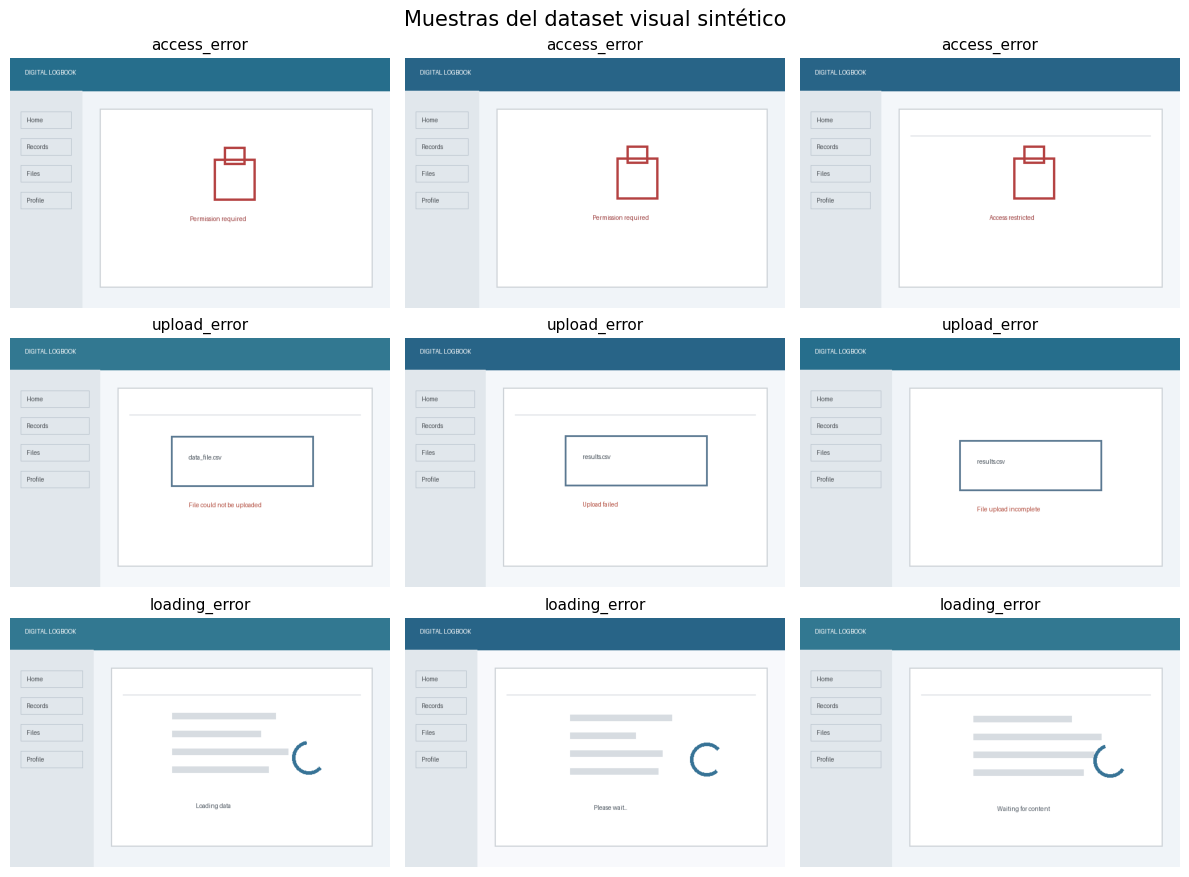

In [2]:
# ================================================================
# CELDA 11 - INSPECCIÓN VISUAL DEL DATASET SINTÉTICO
# ================================================================

import matplotlib.pyplot as plt
from PIL import Image

# Seleccionar tres ejemplos reproducibles por categoría
sample_positions = [0, 10, 20]

fig, axes = plt.subplots(
    len(CLASSES),
    len(sample_positions),
    figsize=(12, 9)
)

for row, class_name in enumerate(CLASSES):

    image_files = sorted(
        (DATASET_DIR / class_name).glob("*.png")
    )

    for col, position in enumerate(sample_positions):

        image_path = image_files[position]
        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        axes[row, col].set_title(
            class_name,
            fontsize=11
        )

plt.suptitle(
    "Muestras del dataset visual sintético",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [6]:
# ================================================================
# CELDA 12 - DIVISIÓN DEL DATASET VISUAL
# ================================================================

from pathlib import Path
import random
import shutil

# Configuración reproducible
random.seed(42)

SPLIT_DIR = Path("/content/dataset_visual_split")
SPLITS = ["train", "validation", "test"]

# Recrear la carpeta de particiones para evitar duplicados
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

# Crear estructura de carpetas
for split in SPLITS:
    for class_name in CLASSES:
        (SPLIT_DIR / split / class_name).mkdir(
            parents=True,
            exist_ok=True
        )

# Dividir cada clase de forma independiente
for class_name in CLASSES:

    image_files = sorted(
        (DATASET_DIR / class_name).glob("*.png")
    )

    # Mezcla reproducible
    random.shuffle(image_files)

    total = len(image_files)

    train_end = int(total * 0.60)
    validation_end = train_end + int(total * 0.20)

    train_files = image_files[:train_end]
    validation_files = image_files[train_end:validation_end]
    test_files = image_files[validation_end:]

    split_files = {
        "train": train_files,
        "validation": validation_files,
        "test": test_files
    }

    # Copiar las imágenes a sus particiones
    for split, files in split_files.items():
        for source_file in files:

            destination = (
                SPLIT_DIR
                / split
                / class_name
                / source_file.name
            )

            shutil.copy2(source_file, destination)

# ================================================================
# VALIDACIÓN DE LAS PARTICIONES
# ================================================================

print("=" * 70)
print("DIVISIÓN DEL DATASET VISUAL")
print("=" * 70)

grand_total = 0

for split in SPLITS:

    print(f"\n{split.upper()}")
    split_total = 0

    for class_name in CLASSES:

        count = len(
            list(
                (SPLIT_DIR / split / class_name).glob("*.png")
            )
        )

        split_total += count

        print(f"  {class_name}: {count} imágenes")

    grand_total += split_total

    print(f"  Total {split}: {split_total} imágenes")

print("-" * 70)
print(f"Total general: {grand_total} imágenes")
print("\nResultado: división del dataset visual completada.")

DIVISIÓN DEL DATASET VISUAL

TRAIN
  access_error: 18 imágenes
  upload_error: 18 imágenes
  loading_error: 18 imágenes
  Total train: 54 imágenes

VALIDATION
  access_error: 6 imágenes
  upload_error: 6 imágenes
  loading_error: 6 imágenes
  Total validation: 18 imágenes

TEST
  access_error: 6 imágenes
  upload_error: 6 imágenes
  loading_error: 6 imágenes
  Total test: 18 imágenes
----------------------------------------------------------------------
Total general: 90 imágenes

Resultado: división del dataset visual completada.


In [7]:
# ================================================================
# CELDA 13 - CARGA DEL DATASET VISUAL
# ================================================================

import tensorflow as tf

# Configuración de las imágenes
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

# Dataset de entrenamiento
train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Dataset de validación
validation_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Dataset de prueba
test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Nombres de las clases detectadas
class_names_visual = train_ds.class_names

print("\n" + "=" * 70)
print("CARGA DEL DATASET VISUAL")
print("=" * 70)

print("Clases detectadas:", class_names_visual)
print("Número de clases:", len(class_names_visual))
print("Tamaño de entrada:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

print("\nImágenes esperadas por partición:")
print("Train: 54")
print("Validation: 18")
print("Test: 18")

print("\nResultado: dataset visual cargado correctamente.")

Found 54 files belonging to 3 classes.
Found 18 files belonging to 3 classes.
Found 18 files belonging to 3 classes.

CARGA DEL DATASET VISUAL
Clases detectadas: ['access_error', 'loading_error', 'upload_error']
Número de clases: 3
Tamaño de entrada: (224, 224)
Batch size: 8

Imágenes esperadas por partición:
Train: 54
Validation: 18
Test: 18

Resultado: dataset visual cargado correctamente.


In [8]:
# ================================================================
# CELDA 14 - ARQUITECTURA DEL CLASIFICADOR VISUAL
# ================================================================

from tensorflow import keras
from tensorflow.keras import layers

# Data augmentation aplicado únicamente durante entrenamiento
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.05),
    ],
    name="data_augmentation"
)

# Modelo base preentrenado
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Primera etapa de transfer learning:
# congelar los pesos preentrenados
base_model.trainable = False

# Construcción del modelo
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# EfficientNetB0 de Keras incorpora el reescalado
# correspondiente dentro de su implementación.
x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    len(class_names_visual),
    activation="softmax"
)(x)

visual_model = keras.Model(
    inputs,
    outputs,
    name="logbook_visual_classifier"
)

# Compilación
visual_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=" * 70)
print("ARQUITECTURA DEL CLASIFICADOR VISUAL")
print("=" * 70)

print("Modelo base: EfficientNetB0")
print("Pesos preentrenados: ImageNet")
print("Transfer learning: modelo base congelado")
print("Tamaño de entrada: 224 x 224 x 3")
print("Número de clases:", len(class_names_visual))
print("Clases:", class_names_visual)
print("Dropout: 0.30")
print("Learning rate: 0.001")

print("\nResultado: arquitectura visual construida correctamente.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ARQUITECTURA DEL CLASIFICADOR VISUAL
Modelo base: EfficientNetB0
Pesos preentrenados: ImageNet
Transfer learning: modelo base congelado
Tamaño de entrada: 224 x 224 x 3
Número de clases: 3
Clases: ['access_error', 'loading_error', 'upload_error']
Dropout: 0.30
Learning rate: 0.001

Resultado: arquitectura visual construida correctamente.


In [9]:
# ================================================================
# CELDA 15 - ENTRENAMIENTO DEL CLASIFICADOR VISUAL
# ================================================================

from tensorflow import keras

# Callbacks para controlar el entrenamiento
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    "/content/best_visual_model.keras",
    monitor="val_loss",
    save_best_only=True
)

# Entrenamiento
history = visual_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=15,
    callbacks=[
        early_stopping,
        model_checkpoint
    ],
    verbose=1
)

# Resumen final
epochs_completed = len(history.history["loss"])

best_epoch = (
    min(
        range(epochs_completed),
        key=lambda i: history.history["val_loss"][i]
    )
    + 1
)

print("\n" + "=" * 70)
print("RESUMEN DEL ENTRENAMIENTO VISUAL")
print("=" * 70)

print("Épocas ejecutadas:", epochs_completed)
print("Mejor época según val_loss:", best_epoch)

print(
    "Accuracy final de entrenamiento:",
    f"{history.history['accuracy'][-1]:.4f}"
)

print(
    "Accuracy final de validación:",
    f"{history.history['val_accuracy'][-1]:.4f}"
)

print(
    "Mejor val_loss:",
    f"{min(history.history['val_loss']):.4f}"
)

print(
    "Modelo guardado:",
    "/content/best_visual_model.keras"
)

print("\nResultado: entrenamiento visual completado.")


Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.3333 - loss: 1.2160 - val_accuracy: 0.3889 - val_loss: 0.9714
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 989ms/step - accuracy: 0.5556 - loss: 0.9415 - val_accuracy: 0.6667 - val_loss: 0.8467
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 759ms/step - accuracy: 0.6852 - loss: 0.8381 - val_accuracy: 0.6667 - val_loss: 0.7613
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.8889 - loss: 0.6739 - val_accuracy: 1.0000 - val_loss: 0.6164
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 753ms/step - accuracy: 0.8704 - loss: 0.6669 - val_accuracy: 1.0000 - val_loss: 0.5081
Epoch 6/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 943ms/step - accuracy: 0.9630 - loss: 0.5230 - val_accuracy: 1.0000 - val_loss: 0.4466
Epoch 7/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 797ms/step - accuracy: 0.9630 - loss: 0.4650 - val_accuracy: 1.0000 - val_loss: 0.3987
Epoch 8/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 766ms/step - accuracy: 0.9815 - loss: 0.4017 - val_accuracy: 1.0000 - val_loss: 0.34

EVALUACIÓN DEL CLASIFICADOR VISUAL

Accuracy: 1.0000

Classification report:
               precision    recall  f1-score   support

 access_error       1.00      1.00      1.00         6
loading_error       1.00      1.00      1.00         6
 upload_error       1.00      1.00      1.00         6

     accuracy                           1.00        18
    macro avg       1.00      1.00      1.00        18
 weighted avg       1.00      1.00      1.00        18



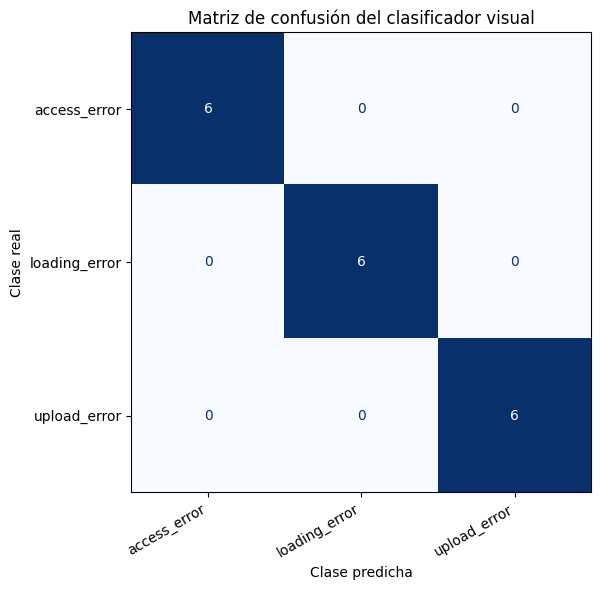


Resultado: evaluación visual completada.


In [10]:
# ================================================================
# CELDA 16 - EVALUACIÓN FINAL DEL CLASIFICADOR VISUAL
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------
# PREDICCIONES SOBRE EL CONJUNTO DE PRUEBA
# ------------------------------------------------

y_true_visual = []
y_pred_visual = []

for images, labels in test_ds:

    probabilities = visual_model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    y_true_visual.extend(
        labels.numpy()
    )

    y_pred_visual.extend(
        predictions
    )

y_true_visual = np.array(y_true_visual)
y_pred_visual = np.array(y_pred_visual)

# ------------------------------------------------
# MÉTRICAS
# ------------------------------------------------

visual_accuracy = accuracy_score(
    y_true_visual,
    y_pred_visual
)

visual_report = classification_report(
    y_true_visual,
    y_pred_visual,
    target_names=class_names_visual,
    zero_division=0
)

visual_cm = confusion_matrix(
    y_true_visual,
    y_pred_visual
)

print("=" * 70)
print("EVALUACIÓN DEL CLASIFICADOR VISUAL")
print("=" * 70)

print(
    f"\nAccuracy: {visual_accuracy:.4f}"
)

print("\nClassification report:")
print(visual_report)

# ------------------------------------------------
# MATRIZ DE CONFUSIÓN GRÁFICA
# ------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=visual_cm,
    display_labels=class_names_visual
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Matriz de confusión del clasificador visual"
)

ax.set_xlabel(
    "Clase predicha"
)

ax.set_ylabel(
    "Clase real"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

print(
    "\nResultado: evaluación visual completada."
)

In [11]:
# ================================================================
# CELDA 17 - INTEGRACIÓN INICIAL TEXTO-IMAGEN
# ================================================================

import numpy as np
import tensorflow as tf

# Relación entre las intenciones textuales y las clases visuales
INTENT_TO_VISUAL_CLASS = {
    "access_permission_issue": "access_error",
    "file_upload_issue": "upload_error",
    "browser_issue": "loading_error"
}


def predict_visual_class(image_path):
    """
    Carga una imagen y obtiene la clase visual,
    su confianza y las probabilidades del modelo.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = tf.expand_dims(image_array, axis=0)

    probabilities = visual_model.predict(
        image_array,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names_visual[predicted_index]
    confidence = float(probabilities[predicted_index])

    return predicted_class, confidence


def multimodal_prediction(text, image_path):
    """
    Procesa una entrada textual y una imagen,
    y comunica una interpretación conjunta.
    """

    # Validación básica del texto
    if text is None or not str(text).strip():
        raise ValueError(
            "La entrada textual no puede estar vacía."
        )

    # Predicción textual
    text_intent = text_model.predict(
        [str(text).strip()]
    )[0]

    # Predicción visual
    visual_class, visual_confidence = predict_visual_class(
        image_path
    )

    # Clase visual esperada según la intención textual
    expected_visual_class = INTENT_TO_VISUAL_CLASS.get(
        text_intent
    )

    # Interpretación conjunta
    if expected_visual_class is None:

        interpretation = (
            "La intención textual no tiene una clase visual "
            "equivalente en el alcance actual del prototipo."
        )

        consistency = "sin equivalencia visual"

    elif expected_visual_class == visual_class:

        interpretation = (
            "La descripción textual y la clasificación visual "
            "son consistentes con el mismo tipo de problema."
        )

        consistency = "coincidencia"

    else:

        interpretation = (
            "La descripción textual y la imagen indican "
            "categorías diferentes, por lo que se requiere "
            "revisar ambas entradas."
        )

        consistency = "diferencia"

    result = {
        "texto": str(text).strip(),
        "intencion_textual": text_intent,
        "clase_visual": visual_class,
        "confianza_visual": visual_confidence,
        "consistencia": consistency,
        "interpretacion": interpretation
    }

    return result


print("=" * 70)
print("INTEGRACIÓN MULTIMODAL")
print("=" * 70)

print("Intenciones con equivalencia visual:")

for intent, visual_class in INTENT_TO_VISUAL_CLASS.items():
    print(f"- {intent} -> {visual_class}")

print(
    "\nResultado: función de integración multimodal preparada."
)

INTEGRACIÓN MULTIMODAL
Intenciones con equivalencia visual:
- access_permission_issue -> access_error
- file_upload_issue -> upload_error
- browser_issue -> loading_error

Resultado: función de integración multimodal preparada.


PRUEBA MULTIMODAL - CASO CONSISTENTE
Texto de entrada:
No puedo cargar mi archivo PDF en el logbook

Imagen de entrada:
upload_error_001.png

RESULTADOS
----------------------------------------------------------------------
Intención textual: file_upload_issue
Clase visual: upload_error
Confianza visual: 74.99%
Consistencia: coincidencia

Interpretación:
La descripción textual y la clasificación visual son consistentes con el mismo tipo de problema.


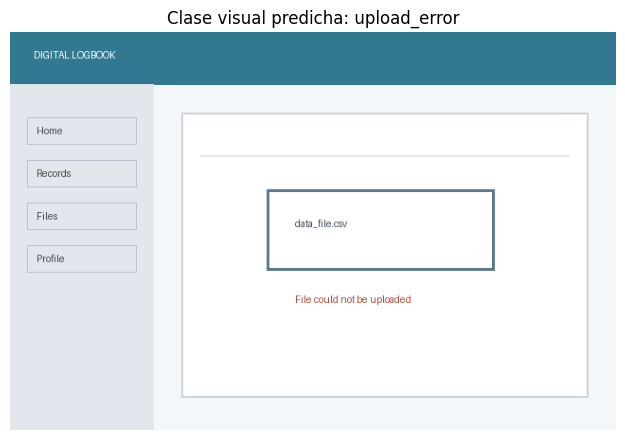

In [22]:
# ================================================================
# CELDA 18 - PRUEBA END-TO-END DE INTEGRACIÓN MULTIMODAL
# ================================================================

# Seleccionar una imagen de prueba de la clase upload_error
test_image_path = sorted(
    (SPLIT_DIR / "test" / "upload_error").glob("*.png")
)[0]

# Texto de prueba
test_text = "No puedo cargar mi archivo PDF en el logbook"

print("=" * 70)
print("PRUEBA MULTIMODAL - CASO CONSISTENTE")
print("=" * 70)

print("Texto de entrada:")
print(test_text)

print("\nImagen de entrada:")
print(test_image_path.name)

# Ejecutar la función multimodal definida en la Celda 17
result = multimodal_prediction(
    test_text,
    test_image_path
)

print("\nRESULTADOS")
print("-" * 70)

print("Intención textual:", result["intencion_textual"])
print("Clase visual:", result["clase_visual"])
print(
    "Confianza visual:",
    f"{result['confianza_visual']:.2%}"
)
print("Consistencia:", result["consistencia"])

print("\nInterpretación:")
print(result["interpretacion"])

# Mostrar la imagen utilizada
image = Image.open(test_image_path)

plt.figure(figsize=(7, 4.5))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Clase visual predicha: {result['clase_visual']}"
)
plt.tight_layout()
plt.show()

PRUEBA MULTIMODAL - CASO CON DIFERENCIA

Texto de entrada:
No tengo permisos para acceder a esta sección del logbook

Imagen de entrada:
upload_error_006.png

RESULTADOS
----------------------------------------------------------------------
Intención textual: access_permission_issue
Clase visual: upload_error
Confianza visual: 83.6%
Consistencia: diferencia

Interpretación:
La descripción textual y la imagen indican categorías diferentes, por lo que se requiere revisar ambas entradas.


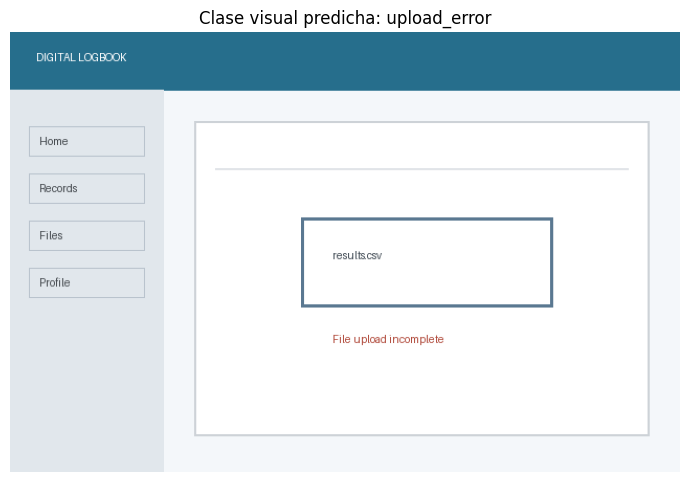

In [23]:
# ================================================================
# CELDA 18 - PRUEBA MULTIMODAL: CASO CON DIFERENCIA
# ================================================================

import matplotlib.pyplot as plt
from PIL import Image

# Texto asociado con un problema de acceso
test_text = "No tengo permisos para acceder a esta sección del logbook"

# Utilizar una imagen de prueba perteneciente a upload_error
test_image_path = sorted(
    (SPLIT_DIR / "test" / "upload_error").glob("*.png")
)[1]

# Ejecutar integración multimodal
result = multimodal_prediction(
    test_text,
    str(test_image_path)
)

print("=" * 70)
print("PRUEBA MULTIMODAL - CASO CON DIFERENCIA")
print("=" * 70)

print("\nTexto de entrada:")
print(result["texto"])

print("\nImagen de entrada:")
print(test_image_path.name)

print("\nRESULTADOS")
print("-" * 70)

print(
    "Intención textual:",
    result["intencion_textual"]
)

print(
    "Clase visual:",
    result["clase_visual"]
)

print(
    "Confianza visual:",
    f"{result['confianza_visual']:.1%}"
)

print(
    "Consistencia:",
    result["consistencia"]
)

print("\nInterpretación:")
print(result["interpretacion"])

# Mostrar la imagen utilizada
image = Image.open(test_image_path)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Clase visual predicha: {result['clase_visual']}"
)

plt.tight_layout()
plt.show()

PRUEBA MULTIMODAL - SIN EQUIVALENCIA VISUAL

Texto de entrada:
Mi cuenta nueva todavía no aparece en el logbook

Imagen de entrada:
loading_error_007.png

RESULTADOS
----------------------------------------------------------------------
Intención textual: account_sync_issue
Clase visual: loading_error
Confianza visual: 94.0%
Consistencia: sin equivalencia visual

Interpretación:
La intención textual no tiene una clase visual equivalente en el alcance actual del prototipo.


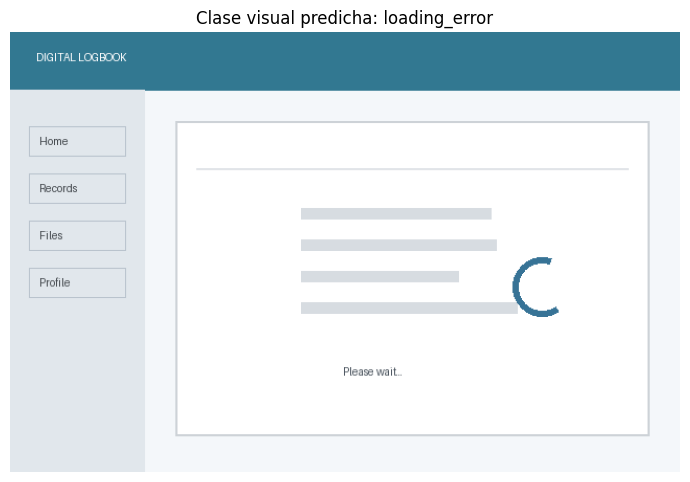

In [26]:
# ================================================================
# CELDA 19 - PRUEBA MULTIMODAL: SIN EQUIVALENCIA VISUAL
# ================================================================

import matplotlib.pyplot as plt
from PIL import Image

# Esta consulta corresponde a una intención textual que
# no tiene una categoría visual equivalente en el prototipo.
test_text = "Mi cuenta nueva todavía no aparece en el logbook"

# Se proporciona una imagen válida del dataset visual.
test_image_path = sorted(
    (SPLIT_DIR / "test" / "loading_error").glob("*.png")
)[0]

# Ejecutar integración multimodal
result = multimodal_prediction(
    test_text,
    str(test_image_path)
)

print("=" * 70)
print("PRUEBA MULTIMODAL - SIN EQUIVALENCIA VISUAL")
print("=" * 70)

print("\nTexto de entrada:")
print(result["texto"])

print("\nImagen de entrada:")
print(test_image_path.name)

print("\nRESULTADOS")
print("-" * 70)

print(
    "Intención textual:",
    result["intencion_textual"]
)

print(
    "Clase visual:",
    result["clase_visual"]
)

print(
    "Confianza visual:",
    f"{result['confianza_visual']:.1%}"
)

print(
    "Consistencia:",
    result["consistencia"]
)

print("\nInterpretación:")
print(result["interpretacion"])

# Mostrar la imagen utilizada
image = Image.open(test_image_path)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Clase visual predicha: {result['clase_visual']}"
)

plt.tight_layout()
plt.show()

PRUEBA MULTIMODAL - CASO CONSISTENTE

Texto de entrada:
No puedo cargar mi archivo PDF en el logbook

Imagen de entrada:
upload_error_001.png

RESULTADOS
----------------------------------------------------------------------
Intención textual: file_upload_issue
Clase visual: upload_error
Confianza visual: 75.0%
Consistencia: coincidencia

Interpretación:
La descripción textual y la clasificación visual son consistentes con el mismo tipo de problema.


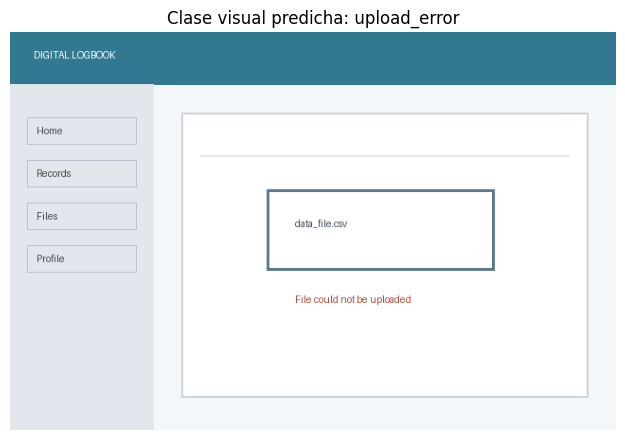

In [25]:
# ================================================================
# CELDA 19 - PRUEBA MULTIMODAL: CASO CONSISTENTE
# ================================================================

# Texto relacionado con problemas de carga de archivos
test_text = "No puedo cargar mi archivo PDF en el logbook"

# Seleccionar una imagen de prueba de upload_error
test_image_path = sorted(
    (SPLIT_DIR / "test" / "upload_error").glob("*.png")
)[0]

print("=" * 70)
print("PRUEBA MULTIMODAL - CASO CONSISTENTE")
print("=" * 70)

print("\nTexto de entrada:")
print(test_text)

print("\nImagen de entrada:")
print(test_image_path.name)

# Ejecutar integración multimodal definida en la Celda 17
result = multimodal_prediction(
    test_text,
    test_image_path
)

print("\nRESULTADOS")
print("-" * 70)

print("Intención textual:", result["intencion_textual"])
print("Clase visual:", result["clase_visual"])
print(
    "Confianza visual:",
    f"{result['confianza_visual']:.1%}"
)
print("Consistencia:", result["consistencia"])

print("\nInterpretación:")
print(result["interpretacion"])

# Mostrar la imagen evaluada
image = Image.open(test_image_path)

plt.figure(figsize=(7, 4.5))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Clase visual predicha: {result['clase_visual']}"
)
plt.tight_layout()
plt.show()

PRUEBA MULTIMODAL - CASO CON INFORMACIÓN DIFERENTE

Texto de entrada:
No tengo permisos para acceder a esta función

Imagen de entrada:
upload_error_006.png

RESULTADOS
----------------------------------------------------------------------
Intención textual: access_permission_issue
Clase visual: upload_error
Confianza visual: 83.6%
Consistencia: diferencia

Interpretación:
La descripción textual y la imagen indican categorías diferentes, por lo que se requiere revisar ambas entradas.


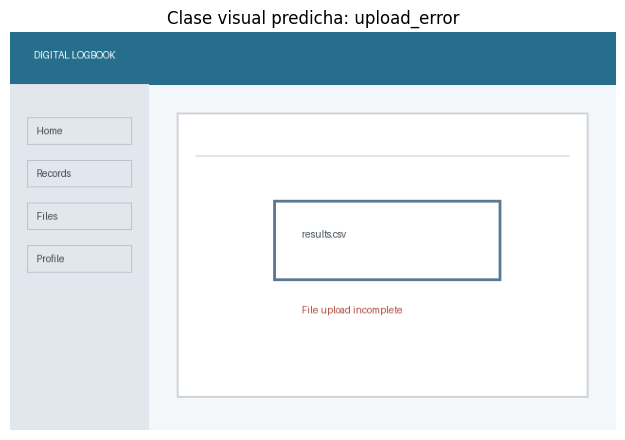

In [27]:
# ================================================================
# CELDA 20 - PRUEBA MULTIMODAL: TEXTO E IMAGEN DIFERENTES
# ================================================================

# Texto relacionado con un problema de acceso
test_text = "No tengo permisos para acceder a esta función"

# Imagen perteneciente a la clase upload_error
test_image_path = sorted(
    (SPLIT_DIR / "test" / "upload_error").glob("*.png")
)[1]

print("=" * 70)
print("PRUEBA MULTIMODAL - CASO CON INFORMACIÓN DIFERENTE")
print("=" * 70)

print("\nTexto de entrada:")
print(test_text)

print("\nImagen de entrada:")
print(test_image_path.name)

# Ejecutar la integración multimodal
result = multimodal_prediction(
    test_text,
    test_image_path
)

print("\nRESULTADOS")
print("-" * 70)

print("Intención textual:", result["intencion_textual"])
print("Clase visual:", result["clase_visual"])

print(
    "Confianza visual:",
    f"{result['confianza_visual']:.1%}"
)

print("Consistencia:", result["consistencia"])

print("\nInterpretación:")
print(result["interpretacion"])

# Mostrar imagen utilizada
image = Image.open(test_image_path)

plt.figure(figsize=(7, 4.5))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Clase visual predicha: {result['clase_visual']}"
)

plt.tight_layout()
plt.show()